# ReviewLens - 03 POS tagging (steps 17-19)
**Part-of-Speech tagging** labels every word as a noun, adjective, verb, etc.  For reviews this separates *what people talk about* (nouns: price, quality, size, delivery) from *how they feel* (adjectives: bekaar, zabardast, kharab).

**The catch:** standard taggers (NLTK, spaCy) are trained on English. Our reviews are mostly Roman Urdu (Urdu written in English letters), so:
1. we first **measure** how badly a standard tagger does on Roman Urdu (step 17),
2. we build a small **Roman Urdu word list** with tags (step 18),
3. we combine both into one tagger and turn the tags into columns, pairs and charts (step 19).

Needs: `pip install nltk wordcloud networkx` (the notebook still runs without nltk and wordcloud, with fewer features).

In [51]:
import warnings; warnings.filterwarnings("ignore")
import os, re
from collections import Counter, defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
os.makedirs("../docs", exist_ok=True)

df = pd.read_csv("../data/reviews_for_nlp.csv")
df["review_clean"] = df["review_clean"].fillna("")
def tokenize(text): return re.findall(r"[a-z]+", text.lower())
df["tokens"] = df["review_clean"].map(tokenize)
print(df.shape, "| total tokens:", df.tokens.str.len().sum())

(3923, 7) | total tokens: 96246


## 1. Is the standard English tagger available?

In [52]:
HAVE_NLTK = False
try:
    import nltk
    for res in ["averaged_perceptron_tagger_eng", "averaged_perceptron_tagger", "words"]:
        try: nltk.download(res, quiet=True)
        except Exception: pass
    print(nltk.pos_tag(["good", "quality", "product"]))
    HAVE_NLTK = True
except Exception as e:
    print("NLTK tagger not available:", type(e).__name__, "- run: pip install nltk  (the rest still works)")
print("HAVE_NLTK =", HAVE_NLTK)

# Map NLTK's fine Penn tags to our coarse tags
def penn_to_coarse(tag):
    if tag.startswith("NN"): return "NOUN"
    if tag.startswith("JJ"): return "ADJ"
    if tag.startswith("VB") or tag == "MD": return "VERB"
    if tag.startswith("RB"): return "ADV"
    if tag.startswith("PRP") or tag in ("WP", "WP$"): return "PRON"
    return "OTHER"
def nltk_tags(tokens):
    return [penn_to_coarse(t) for _, t in nltk.pos_tag(tokens)] if HAVE_NLTK else ["?"] * len(tokens)

[('good', 'JJ'), ('quality', 'NN'), ('product', 'NN')]
HAVE_NLTK = True


## 2. Step 17 - Test the standard tagger on 30 reviews
We take 15 Roman Urdu reviews and 15 English/mixed reviews, and the first 12 words of each.
1. Run the next cell: it creates `../docs/pos_test_sample.csv`.
2. Open it in Excel and fill **my_tag** for each word with one of: `NOUN`, `ADJ`, `VERB`, `ADV`, `PRON`, `OTHER`
   (OTHER = everything else: *aur, ka, ko, hai, nahi, the, and ...*; helper verbs like *hai/tha* count as VERB if you prefer, but be consistent).
3. Save as CSV and run the evaluation cell further down (after step 4).

In [53]:
rng = np.random.default_rng(42)
ru = df[(df.language == "Roman Urdu") & df.tokens.str.len().between(8, 25)]
en = df[(df.language.isin(["English", "Mixed"])) & df.tokens.str.len().between(8, 25)]
pick = pd.concat([ru.sample(15, random_state=42).assign(group="Roman Urdu"),
                  en.sample(15, random_state=42).assign(group="English/Mixed")])
rows = []
for _, r in pick.iterrows():
    toks = r.tokens[:12]; tg = nltk_tags(toks)
    for i, (t, g) in enumerate(zip(toks, tg)):
        rows.append([r.review_key, r.group, i + 1, t, g, ""])
sample = pd.DataFrame(rows, columns=["review_key", "group", "position", "token", "nltk_tag", "my_tag"])
path = "../docs/pos_test_sample.csv"
if os.path.exists(path): print("pos_test_sample.csv already exists - NOT overwritten (your tags are safe).")
else: sample.to_csv(path, index=False, encoding="utf-8-sig"); print("Created", path, "with", len(sample), "words")
sample.head(14)

pos_test_sample.csv already exists - NOT overwritten (your tags are safe).


,review_key,group,position,token,nltk_tag,my_tag
0,3592,Roman Urdu,1,mujhe,NOUN,
1,3592,Roman Urdu,2,order,NOUN,
2,3592,Roman Urdu,3,mil,NOUN,
3,3592,Roman Urdu,4,gia,NOUN,
4,3592,Roman Urdu,5,ur,ADJ,
5,3592,Roman Urdu,6,bohat,PRON,
6,3592,Roman Urdu,7,pasan,ADJ,
7,3592,Roman Urdu,8,aya,NOUN,
8,3592,Roman Urdu,9,acha,NOUN,
9,3592,Roman Urdu,10,qeemat,NOUN,


## 3. Step 18 - The Roman Urdu word list (lexicon)
`../data/roman_urdu_pos_lexicon.csv` holds the most frequent words with a **draft** tag for each.
**Your job:** open it in Excel, correct any wrong tags, and fill in the blank ones (start from the top; the most frequent words matter most).
Allowed tags: `NOUN PROPN ADJ VERB AUX ADV PRON DET ADP CONJ PART NUM`.
(`AUX` = helper verbs like *hai, tha, raha*; `ADP` = postpositions like *ka, ko, se, mein*.)

In [54]:
LEX_PATH = "../data/roman_urdu_pos_lexicon.csv"
if not os.path.exists(LEX_PATH):                       # first-time: create an empty template from the data
    freq = Counter(t for ts in df.tokens for t in ts)
    pd.DataFrame([(w, n, "", "") for w, n in freq.most_common(450)], columns=["token", "freq", "pos", "status"]).to_csv(LEX_PATH, index=False)
    print("Created an empty lexicon template at", LEX_PATH)
lex_df = pd.read_csv(LEX_PATH).fillna("")
LEXICON = dict(zip(lex_df.token, lex_df.pos.str.upper().str.strip()))
LEXICON = {w: p for w, p in LEXICON.items() if p}
freq = Counter(t for ts in df.tokens for t in ts); total = sum(freq.values())
covered = sum(n for w, n in freq.items() if w in LEXICON)
print(f"Lexicon has {len(LEXICON)} tagged words and covers {covered / total * 100:.1f}% of all word occurrences")
print("\nMost frequent words that are NOT tagged yet (add these in Excel):")
print([w for w, _ in freq.most_common(500) if w not in LEXICON][:50])
print("\nTag distribution in the lexicon:"); print(pd.Series(LEXICON).value_counts().to_dict())

Lexicon has 450 tagged words and covers 76.8% of all word occurrences

Most frequent words that are NOT tagged yet (add these in Excel):
['haath', 'bajaye', 'karo', 'kin', 'mausam', 'apna', 'unhon', 'halki', 'rakhta', 'comfortable', 'nice', 'like', 'dikhaya', 'result', 'karein', 'lya', 'dosra', 'jitna', 'up', 'website', 'inhen', 'samaan', 'balkay', 'khilona', 'with', 'alag', 'kamal', 'shukria', 'ps', 'shaamil', 'pi', 'masool', 'haal', 'choti', 'note', 'color', 'safaid', 'satke', 'halkay', 'fabric', 'perfect', 'graphics', 'jb', 'karni', 'karkardagi', 'faraham', 'shuda', 'mojood', 'aisi', 'taakay']

Tag distribution in the lexicon:
{'NOUN': 119, 'VERB': 96, 'ADJ': 80, 'OTHER': 66, 'PRON': 45, 'ADV': 44}


**Finding:** write the coverage percentage and how many words you tagged by hand. Frequent words cover most of the text, so a few hundred words is enough for a good first tagger.

## 4. Step 19 - One tagger that combines both
For each word: **1)** look it up in the Roman Urdu lexicon; **2)** if it is not there but looks like an English word, use the NLTK tag of the whole sentence; **3)** otherwise mark it `UNK` (unknown).

In [55]:
ENGLISH = set()
try:
    from nltk.corpus import words as nltk_words
    ENGLISH = {w.lower() for w in nltk_words.words()}
except Exception:
    pass
ENGLISH |= set("good bad nice great best product price quality size fit color colour delivery fast battery sound screen cover phone camera watch shirt jacket very it its this was the and for with".split())
ENGLISH -= set(LEXICON)            # anything in the lexicon is decided by the lexicon

def tag_review(tokens):
    nt = nltk_tags(tokens) if HAVE_NLTK else None
    out = []
    for i, t in enumerate(tokens):
        if t in LEXICON: out.append(LEXICON[t])
        elif t in ENGLISH and nt is not None: out.append(nt[i])
        else: out.append("UNK")
    return out
df["tags"] = df.tokens.map(tag_review)
print(list(zip(df.tokens.iloc[1], df.tags.iloc[1])))
print(list(zip(df.tokens.iloc[4], df.tags.iloc[4])))
print("\nShare of word occurrences by tag:")
print((pd.Series(Counter(t for ts in df.tags for t in ts)) / total * 100).round(1).sort_values(ascending=False).to_dict())

[('aram', 'NOUN'), ('sy', 'OTHER'), ('pocket', 'NOUN'), ('may', 'OTHER'), ('aa', 'VERB'), ('jta', 'UNK'), ('hai', 'VERB'), ('aur', 'OTHER'), ('quality', 'NOUN'), ('b', 'OTHER'), ('acha', 'ADJ'), ('hai', 'VERB')]
[('shru', 'UNK'), ('may', 'OTHER'), ('may', 'OTHER'), ('thumb', 'VERB'), ('grip', 'NOUN'), ('k', 'OTHER'), ('khalif', 'UNK'), ('thi', 'VERB'), ('kyu', 'NOUN'), ('k', 'OTHER'), ('extra', 'ADJ'), ('chezy', 'UNK'), ('add', 'VERB'), ('kar', 'VERB'), ('deti', 'UNK'), ('thi', 'VERB'), ('lakin', 'OTHER'), ('jb', 'UNK'), ('sy', 'OTHER'), ('meri', 'PRON'), ('stock', 'NOUN'), ('controller', 'NOUN'), ('ki', 'OTHER'), ('rubber', 'NOUN'), ('wire', 'NOUN'), ('kharab', 'ADJ'), ('hona', 'VERB'), ('churu', 'UNK'), ('hoei', 'UNK'), ('may', 'OTHER'), ('ny', 'OTHER'), ('inn', 'VERB'), ('grips', 'UNK'), ('ko', 'OTHER'), ('khared', 'UNK'), ('aur', 'OTHER'), ('may', 'OTHER'), ('bhot', 'ADV'), ('kush', 'UNK'), ('ho', 'VERB'), ('in', 'OTHER'), ('pair', 'NOUN'), ('ko', 'OTHER'), ('istemail', 'UNK'), ('k

### Evaluate against your hand tags (step 17 result)

In [56]:
COARSE = {"NOUN": "NOUN", "PROPN": "NOUN", "ADJ": "ADJ", "VERB": "VERB", "AUX": "VERB", "ADV": "ADV", "PRON": "PRON"}
def coarse(t): return COARSE.get(str(t).upper().strip(), "OTHER")

s = pd.read_csv("../docs/pos_test_sample.csv").fillna("")
s = s[s.my_tag.str.strip() != ""].copy()
print(f"{len(s)} words hand-tagged")
if len(s) < 100:
    print("Fill the my_tag column (at least 100 words) before reading these numbers.")
else:
    s["my"] = s.my_tag.map(coarse)
    s["lexicon_tagger"] = s.token.map(lambda t: coarse(LEXICON.get(t, "UNK")) if t in LEXICON else "OTHER")
    s["hybrid"] = [coarse(LEXICON[t]) if t in LEXICON else (c if c != "?" else "OTHER") for t, c in zip(s.token, s.nltk_tag)]
    s["nltk"] = s.nltk_tag.map(lambda t: t if t != "?" else "OTHER")
    res = []
    for g, part in list(s.groupby("group")) + [("All", s)]:
        res.append([g, len(part)] + [round((part.my == part[c]).mean() * 100, 1) for c in ["nltk", "hybrid"]])
    print(pd.DataFrame(res, columns=["group", "words", "NLTK alone %", "Lexicon + NLTK %"]).to_string(index=False))
    print("\nTo see where NLTK goes wrong on Roman Urdu:")
    bad = s[(s.group == "Roman Urdu") & (s.my != s.nltk)][["token", "nltk", "my"]].head(15)
    print(bad.to_string(index=False))

331 words hand-tagged
        group  words  NLTK alone %  Lexicon + NLTK %
English/Mixed    161          48.4              85.1
   Roman Urdu    170          22.4              86.5
          All    331          35.0              85.8

To see where NLTK goes wrong on Roman Urdu:
    token nltk    my
    mujhe NOUN  PRON
      mil NOUN  VERB
      gia NOUN  VERB
       ur  ADJ OTHER
    bohat PRON   ADV
      aya NOUN  VERB
     acha NOUN   ADJ
       ur  ADJ OTHER
darmiyani NOUN   ADJ
khareedne NOUN  VERB
       ka NOUN OTHER
     soch NOUN  VERB
     raha NOUN  VERB
      hon NOUN  VERB
    kabhi NOUN   ADV


**Finding:** compare NLTK accuracy on English/Mixed versus Roman Urdu. A big gap proves the standard tagger is not suitable for Roman Urdu and justifies the custom lexicon. (If NLTK is not installed, the NLTK column is empty - install it first.)

## 5. Turn tags into data (the 'numerical features' from the lecture)
Per review: noun, adjective and verb counts.  Then **adjective-noun pairs**: each adjective is linked to the nearest noun within 2 words (*bekaar quality*, *size chota*).  A negation word nearby (*nahi, nah, na, nai*) flips the meaning, so we record `negated`.

In [57]:
ASPECT = {  # unify spellings and synonyms so the same aspect is counted once
 "price": ["qeemat", "keemat", "price", "paisay", "hisaab"], "quality": ["miyaar", "mayar", "quality", "mawaad", "material"],
 "product": ["masnoaat", "product", "cheez", "chez", "cheeze", "item", "stuff"], "delivery": ["tarseel", "delivery"],
 "packing": ["packing", "pack"], "size": ["size", "fitting"], "colour": ["rang", "colour", "color"],
 "experience": ["tajurbah", "experience"], "design": ["design", "silai"], "service": ["service", "madad", "khidmat"],
 "function": ["kaam"], "usage": ["istemaal"],
}
# nouns that carry no business meaning on their own (e.g. 'tor' in 'tor par' = 'by way of'); skipped when making pairs
GENERIC = {"tor", "terhan", "tarah", "baat", "din", "waqt", "time", "taraf", "baar", "saal", "jagah", "lehaz", "nazar", "hadd"}
CANON = {w: a for a, ws in ASPECT.items() for w in ws}
NEG = {"nahi", "nah", "na", "nai", "not", "no", "nahin"}

feat, pairs = [], []
for key, toks, tags in zip(df.review_key, df.tokens, df.tags):
    feat.append([key, len(toks), tags.count("NOUN") + tags.count("PROPN"), tags.count("ADJ"), tags.count("VERB"), tags.count("PRON")])
    nouns = [i for i, t in enumerate(tags) if t in ("NOUN", "PROPN") and toks[i] not in GENERIC]
    for i, t in enumerate(tags):
        if t != "ADJ" or not nouns: continue
        j = min(nouns, key=lambda n: (abs(n - i), n))
        if abs(j - i) <= 2:
            negated = int(any(w in NEG for w in toks[max(0, i - 2): i + 3]))
            pairs.append([key, CANON.get(toks[j], toks[j]), toks[i], negated])
pos_features = pd.DataFrame(feat, columns=["review_key", "token_count", "noun_count", "adj_count", "verb_count", "pron_count"])
pairs_df = pd.DataFrame(pairs, columns=["review_key", "aspect", "opinion", "negated"])
pos_features.to_csv("../data/pos_features.csv", index=False, lineterminator="\n")
pairs_df.to_csv("../data/aspect_opinion_pairs.csv", index=False, lineterminator="\n")
print("pos_features.csv      :", pos_features.shape)
print("aspect_opinion_pairs.csv:", pairs_df.shape, "| reviews with at least one pair:", pairs_df.review_key.nunique())
pairs_df.sample(10, random_state=1)

pos_features.csv      : (3923, 6)
aspect_opinion_pairs.csv: (4379, 4) | reviews with at least one pair: 2514


,review_key,aspect,opinion,negated
133,107,d,uch,0
2387,1891,product,acha,0
4364,3905,price,acha,0
3466,3063,size,chota,0
3982,3498,lock,good,0
1395,1076,quality,acha,0
695,566,product,acha,0
4070,3587,size,sahi,1
772,634,roi,naram,0
2345,1855,product,best,0


These two CSV files are loaded into the warehouse with `sql/09_load_pos.sql`.

## 6. Charts from the lecture table

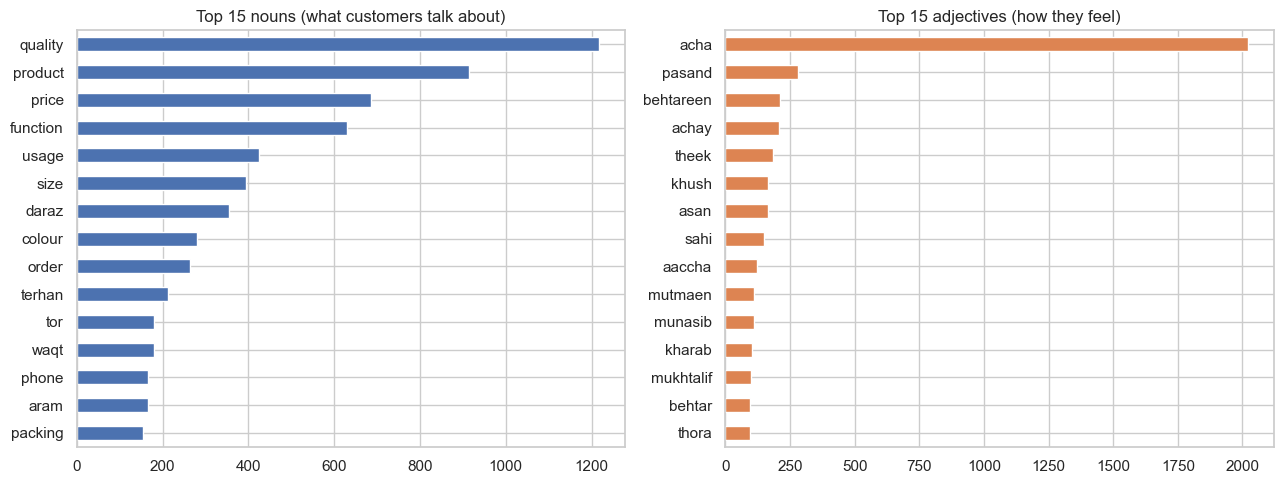

In [58]:
nouns = Counter(CANON.get(t, t) for ts, tg in zip(df.tokens, df.tags) for t, g in zip(ts, tg) if g in ("NOUN", "PROPN"))
adjs = Counter(t for ts, tg in zip(df.tokens, df.tags) for t, g in zip(ts, tg) if g == "ADJ")
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
pd.Series(dict(nouns.most_common(15))).sort_values().plot(kind="barh", color="#4C72B0", ax=ax[0]); ax[0].set_title("Top 15 nouns (what customers talk about)")
pd.Series(dict(adjs.most_common(15))).sort_values().plot(kind="barh", color="#DD8452", ax=ax[1]); ax[1].set_title("Top 15 adjectives (how they feel)")
plt.tight_layout(); plt.savefig("../docs/12_top_nouns_adjectives.png", dpi=150, bbox_inches="tight"); plt.show()

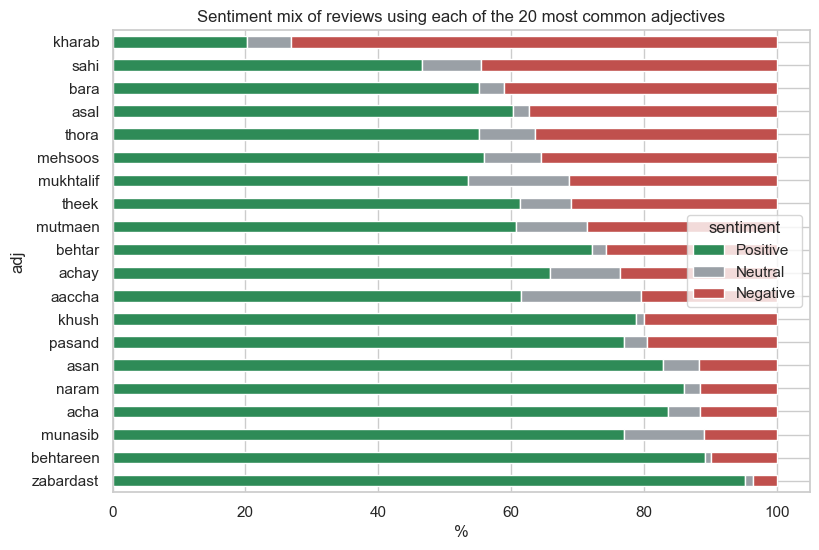

In [59]:
# Do negative reviews use different adjectives? (share of each adjective's uses that sit in Negative reviews)
sent = df.set_index("review_key").sentiment
adj_rows = pd.DataFrame([(sent[k], t) for k, ts, tg in zip(df.review_key, df.tokens, df.tags) for t, g in zip(ts, tg) if g == "ADJ"], columns=["sentiment", "adj"])
top_adj = adj_rows.adj.value_counts().head(20).index
ct = pd.crosstab(adj_rows[adj_rows.adj.isin(top_adj)].adj, adj_rows[adj_rows.adj.isin(top_adj)].sentiment, normalize="index")[["Positive", "Neutral", "Negative"]] * 100
ct = ct.sort_values("Negative")
ct.plot(kind="barh", stacked=True, color=["#2E8B57", "#9AA0A6", "#C0504D"], figsize=(9, 6))
plt.title("Sentiment mix of reviews using each of the 20 most common adjectives"); plt.xlabel("%")
plt.savefig("../docs/13_adjectives_by_sentiment.png", dpi=150, bbox_inches="tight"); plt.show()

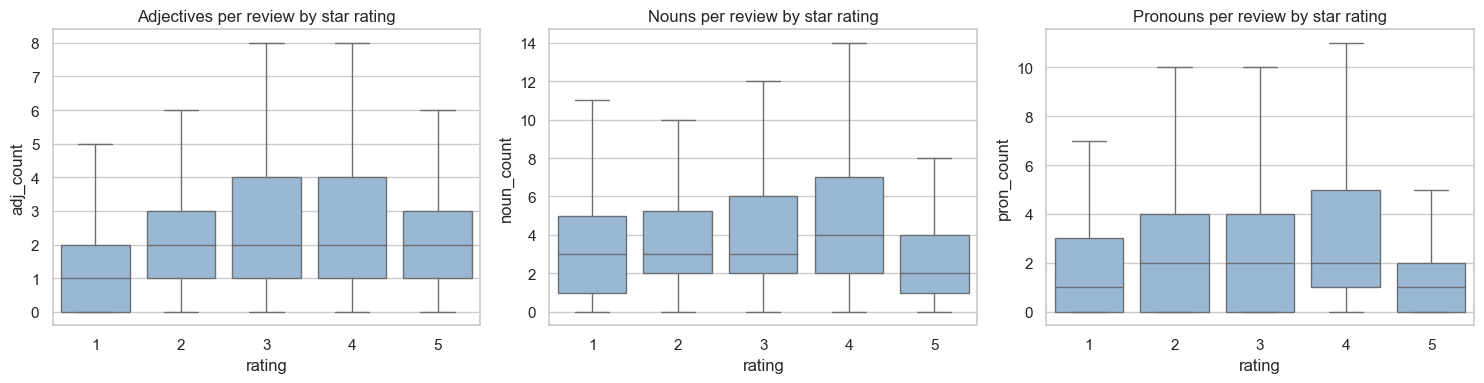

        adj_count  noun_count  verb_count
rating                                   
1            1.35        3.57        4.01
2            2.16        4.08        5.45
3            2.44        4.38        5.53
4            3.07        5.17        6.09
5            1.97        3.29        3.34


In [60]:
# Descriptive reviews vs rating (box plots)
m = pos_features.merge(df[["review_key", "rating"]], on="review_key")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col, ttl in zip(ax, ["adj_count", "noun_count", "pron_count"], ["Adjectives per review", "Nouns per review", "Pronouns per review"]):
    sns.boxplot(data=m, x="rating", y=col, color="#8FB8DE", showfliers=False, ax=a); a.set_title(ttl + " by star rating")
plt.tight_layout(); plt.savefig("../docs/14_pos_counts_by_rating.png", dpi=150, bbox_inches="tight"); plt.show()
print(m.groupby("rating")[["adj_count", "noun_count", "verb_count"]].mean().round(2))

**Finding:** do low-star reviews contain more or fewer adjectives and nouns than 5-star reviews? Write what the box plots show (compare medians).

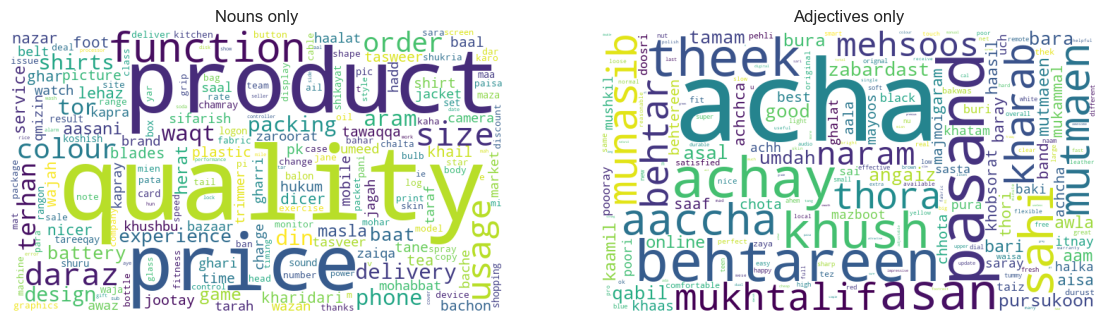

In [61]:
# Separate word clouds: nouns only vs adjectives only
try:
    from wordcloud import WordCloud
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    for a, c, ttl in zip(ax, [nouns, adjs], ["Nouns only", "Adjectives only"]):
        a.imshow(WordCloud(width=700, height=400, background_color="white").generate_from_frequencies(dict(c))); a.axis("off"); a.set_title(ttl)
    plt.savefig("../docs/15_wordclouds_nouns_adjectives.png", dpi=150, bbox_inches="tight"); plt.show()
except ImportError:
    print("wordcloud not installed: pip install wordcloud")

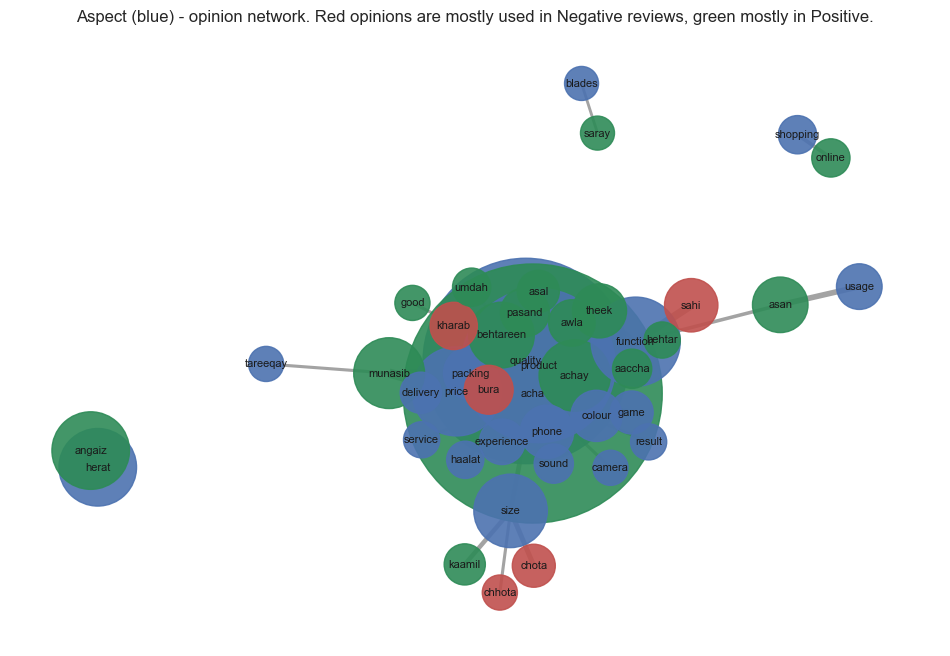

In [62]:
# Noun-adjective network: aspects (blue) linked to the opinions (green/red) used about them
import networkx as nx
top_pairs = pairs_df.groupby(["aspect", "opinion"]).size().sort_values(ascending=False).head(45)
adj_neg = adj_rows.assign(neg=adj_rows.sentiment == "Negative").groupby("adj").neg.mean()
G = nx.Graph()
for (a, o), n in top_pairs.items():
    G.add_edge("N:" + a, "A:" + o, weight=n)
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, k=0.7, seed=3)
sizes = [200 + 40 * sum(d["weight"] for _, _, d in G.edges(n, data=True)) for n in G]
colors = ["#4C72B0" if n.startswith("N:") else ("#C0504D" if adj_neg.get(n[2:], 0.25) > 0.4 else "#2E8B57") for n in G]
nx.draw_networkx_edges(G, pos, width=[0.4 + d["weight"] / 6 for _, _, d in G.edges(data=True)], alpha=0.4)
nx.draw_networkx_nodes(G, pos, node_size=sizes, node_color=colors, alpha=0.9)
nx.draw_networkx_labels(G, pos, labels={n: n[2:] for n in G}, font_size=8)
plt.title("Aspect (blue) - opinion network. Red opinions are mostly used in Negative reviews, green mostly in Positive."); plt.axis("off")
plt.savefig("../docs/16_aspect_opinion_network.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Business view: what do customers complain about?

In [63]:
neg_keys = set(df[df.sentiment == "Negative"].review_key)
pairs_df["neg_review"] = pairs_df.review_key.isin(neg_keys)
pairs_df["opinion_shown"] = np.where(pairs_df.negated == 1, "NOT " + pairs_df.opinion, pairs_df.opinion)   # 'acha nahi' = not good
tbl = pairs_df.groupby("aspect").agg(mentions=("review_key", "size"), in_negative=("neg_review", "sum"))
tbl["negative_share_%"] = (tbl.in_negative / tbl.mentions * 100).round(1)
print("Aspects mentioned at least 40 times, most complained-about first:")
print(tbl[tbl.mentions >= 40].sort_values("negative_share_%", ascending=False).head(12))
print("\nMost common opinion words about the top aspect pairs in NEGATIVE reviews:")
print(pairs_df[pairs_df.neg_review].groupby(["aspect", "opinion_shown"]).size().sort_values(ascending=False).head(12))
print(f"\nPairs with a negation word nearby: {pairs_df.negated.sum()} of {len(pairs_df)} ({pairs_df.negated.mean()*100:.1f}%)")

Aspects mentioned at least 40 times, most complained-about first:
            mentions  in_negative  negative_share_%
aspect                                             
size             172           82              47.7
experience        65           25              38.5
colour           105           31              29.5
quality          785          219              27.9
design            69           19              27.5
phone             67           16              23.9
usage             63           15              23.8
shirts            43           10              23.3
function         165           35              21.2
price            211           41              19.4
product          491           87              17.7
daraz             41            6              14.6

Most common opinion words about the top aspect pairs in NEGATIVE reviews:
aspect    opinion_shown
quality   acha             35
          bura             25
product   acha             21
quality   kharab 

**Finding:** name the aspects with the highest negative share and the opinion words used about them. Also note negation: *acha nahi* (not good) is a complaint even though *acha* is positive, which is why the `negated` column matters.

### About dependency parsing
Dependency parsers need a trained model for the language, and none exists for Roman Urdu. Instead, the adjective-noun pairs above (nearest noun within two words) and the network graph give a lightweight version of "who is described by what". Say this in your report and explain the limitation.